# Cuánto conocimiento oscuro tiene el docente

La destilación de respuesta resultó un empate exacto y la de atención empeoró. Antes de gastar GPU ajustando `ALFA`, la temperatura o el tamaño del estudiante, conviene medir si hay algo que transferir.


In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "corpus.json").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

print("Raíz del proyecto:", ROOT)

FIGURAS = ROOT / "outputs" / "gradcam"
FIGURAS.mkdir(parents=True, exist_ok=True)

Raíz del proyecto: /Users/cristiansandoval/Universidad/Semillero/ButterflyModeling


In [2]:
import numpy as np
import pandas as pd
import tensorflow as tf

from scripts import corpus
from scripts import modelRegistry as registro
from scripts.architectures import preprocessFn
from scripts.dataPipeline import loadSplit, preparar
from scripts.distillation import temperarProbs
from scripts.vizStyle import SERIE_1, SERIE_2, SERIE_3, applyStyle

TEMPERATURAS = (1.0, 2.0, 4.0, 6.0, 8.0)   # 4.0 es la que usaron las dos destilaciones
LOTE = 32

FIGURAS = registro.OUTPUTS_DIR / "figuras"
FIGURAS.mkdir(exist_ok=True)

corpus.materializar()
clases = corpus.classNames()
generos = np.array([c.split("_")[0] for c in clases])
print(f"{len(clases)} clases · {len(set(generos))} géneros")

100 clases · 67 géneros


## 1 · Las distribuciones del docente y del estudiante

Se predicen las probabilidades sobre todo el test con los tres modelos que intervienen: el docente, el estudiante sin destilar y el destilado por respuesta.

In [3]:
MODELOS = {
    "docente": registro.readJson(registro.OUTPUTS_DIR / "teacher.json")["run_id"],
    "estudiante": registro.readJson(registro.OUTPUTS_DIR / "student.json")["run_id"],
}
destilados = [r for r in registro.listRuns() if r.get("distillation") == "respuesta"]
if destilados:
    MODELOS["destilado"] = destilados[0]["run_id"]

probabilidades, verdad = {}, None
for rol, runId in MODELOS.items():
    arquitectura = registro.loadRunConfig(runId)["architecture"]
    modelo = registro.modeloInferencia(runId)
    ds, _ = loadSplit("dataset/test", modelo.input_shape[1:3], LOTE, shuffle=False)
    listo = preparar(ds, preprocessFn(arquitectura))
    probabilidades[rol] = modelo.predict(listo, verbose=0)
    etiquetas = np.concatenate([y.numpy() for _, y in ds]).argmax(axis=1)
    if verdad is None:
        verdad = etiquetas
    assert np.array_equal(etiquetas, verdad), f"{rol} no comparte el orden del test"
    print(f"{rol:11} {arquitectura:20} {probabilidades[rol].shape}")
    del modelo
    tf.keras.backend.clear_session()

Found 5057 files belonging to 100 classes.
docente     efficientnet_b0      (5057, 100)


/opt/miniconda3/envs/semillero/lib/python3.12/site-packages/keras/src/applications/mobilenet_v3.py:454: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(


Found 5057 files belonging to 100 classes.
estudiante  mobilenet_v3_small   (5057, 100)
Found 5057 files belonging to 100 classes.
destilado   mobilenet_v3_small   (5057, 100)


## 2 · Qué queda fuera de la clase ganadora

In [4]:
def resumirTemperatura(probs, temperatura):
    blando = temperarProbs(tf.constant(probs), temperatura).numpy()
    orden = np.sort(blando, axis=1)[:, ::-1]
    entropia = -(blando * np.log(blando + 1e-12)).sum(axis=1) / np.log(blando.shape[1])
    return {
        "entropia_norm": entropia.mean(),
        "masa_top1": orden[:, 0].mean(),
        "masa_fuera_top1": 1 - orden[:, 0].mean(),
        "masa_top2_5": orden[:, 1:5].sum(axis=1).mean(),
        "clases_efectivas": np.exp(entropia * np.log(blando.shape[1])).mean(),
    }

filas = []
for rol in ("docente", "estudiante"):
    for t in TEMPERATURAS:
        filas.append({"rol": rol, "T": t, **resumirTemperatura(probabilidades[rol], t)})
perfil = pd.DataFrame(filas).round(4)
perfil

,rol,T,entropia_norm,masa_top1,masa_fuera_top1,masa_top2_5,clases_efectivas
0,docente,1.0,0.0275,0.9636,0.0364,0.0293,1.3513
1,docente,2.0,0.1899,0.8425,0.1575,0.0645,4.2536
2,docente,4.0,0.8092,0.2820,0.7180,0.1018,43.8010
3,docente,6.0,0.9474,0.1082,0.8918,0.0849,78.7382
4,docente,8.0,0.9772,0.0617,0.9383,0.0726,90.0751
5,estudiante,1.0,0.0540,0.9279,0.0721,0.0569,1.7288
6,estudiante,2.0,0.2499,0.7709,0.2291,0.1015,6.4200
7,estudiante,4.0,0.8132,0.2612,0.7388,0.1203,45.7505
8,estudiante,6.0,0.9455,0.1028,0.8972,0.0947,78.2271
9,estudiante,8.0,0.9758,0.0592,0.9408,0.0789,89.5104


## 3 · ¿La masa sobrante es señal o ruido?

Conocimiento oscuro útil significa que el docente reparte lo que le sobra entre especies plausibles. Si esa masa cayera uniformemente, sería ruido. La referencia es el azar: cada género ocupa su proporción de las 100 clases.

In [5]:
def masaCongenerica(probs, temperatura):
    """Fracción de la masa fuera de la clase ganadora que cae en su mismo género."""
    blando = temperarProbs(tf.constant(probs), temperatura).numpy()
    ganadora = blando.argmax(axis=1)
    mismoGenero = generos[None, :] == generos[ganadora][:, None]
    mismoGenero[np.arange(len(ganadora)), ganadora] = False
    fuera = 1 - blando.max(axis=1)
    congenerica = (blando * mismoGenero).sum(axis=1)
    azar = mismoGenero.sum(axis=1) / (len(clases) - 1)
    return (congenerica / np.maximum(fuera, 1e-9)).mean(), azar.mean()

filas = []
for t in TEMPERATURAS:
    observado, azar = masaCongenerica(probabilidades["docente"], t)
    filas.append({"T": t, "masa_congenerica": round(observado, 4),
                  "azar": round(azar, 4), "veces_el_azar": round(observado / azar, 1)})
congenerica = pd.DataFrame(filas)
congenerica

,T,masa_congenerica,azar,veces_el_azar
0,1.0,0.2352,0.0123,19.1
1,2.0,0.1175,0.0123,9.5
2,4.0,0.0425,0.0123,3.4
3,6.0,0.0278,0.0123,2.2
4,8.0,0.0224,0.0123,1.8


## 4 · Cuánto se diferencian ya docente y estudiante

Es la prueba más directa. La destilación empuja al estudiante hacia la distribución del docente; si a `T=4` esa distancia ya es pequeña, no hay de dónde tirar y el empate se explica solo.

In [6]:
def divergencia(p, q, temperatura):
    bp = temperarProbs(tf.constant(p), temperatura).numpy()
    bq = temperarProbs(tf.constant(q), temperatura).numpy()
    return (bp * (np.log(bp + 1e-12) - np.log(bq + 1e-12))).sum(axis=1).mean()

filas = []
for t in TEMPERATURAS:
    fila = {"T": t,
            "KL(teacher||student)": round(divergencia(
                probabilidades["docente"], probabilidades["estudiante"], t), 4)}
    if "destilado" in probabilidades:
        fila["KL(teacher||distilled)"] = round(divergencia(
            probabilidades["docente"], probabilidades["destilado"], t), 4)
    filas.append(fila)
distancias = pd.DataFrame(filas)
distancias

,T,KL(teacher||student),KL(teacher||distilled)
0,1.0,0.2733,0.3175
1,2.0,0.2208,0.2746
2,4.0,0.1487,0.2784
3,6.0,0.0717,0.1186
4,8.0,0.0407,0.0615


## 5 · Lectura

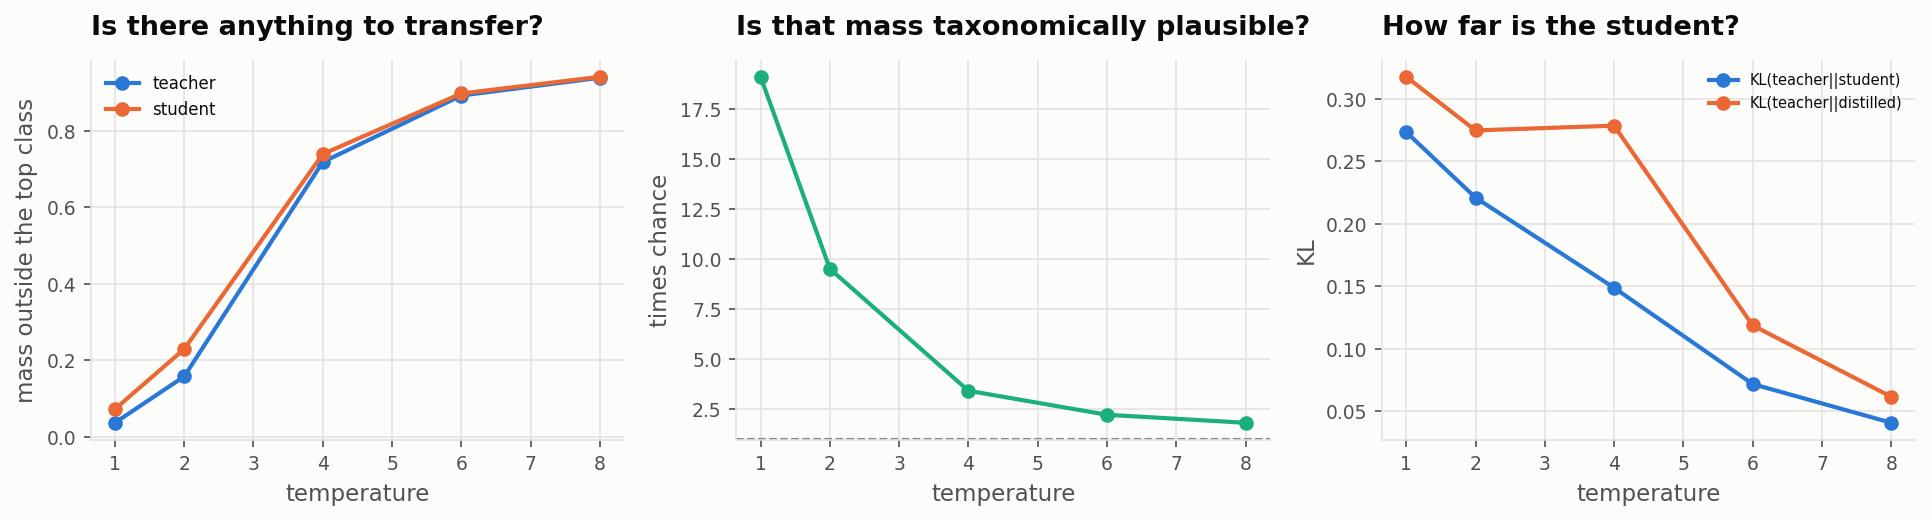

In [7]:
applyStyle()
EN = {"docente": "teacher", "estudiante": "student"}
import matplotlib.pyplot as plt

fig, ejes = plt.subplots(1, 3, figsize=(13, 3.6))
for rol, color in (("docente", SERIE_1), ("estudiante", SERIE_2)):
    sub = perfil[perfil.rol == rol]
    ejes[0].plot(sub["T"], sub["masa_fuera_top1"], "o-", color=color, label=EN[rol])
ejes[0].set(xlabel="temperature", ylabel="mass outside the top class",
            title="Is there anything to transfer?")
ejes[0].legend(frameon=False, fontsize=8)

ejes[1].plot(congenerica["T"], congenerica["veces_el_azar"], "o-", color=SERIE_3)
ejes[1].axhline(1, color="#8a8880", linestyle="--", linewidth=1)
ejes[1].set(xlabel="temperature", ylabel="times chance",
            title="Is that mass taxonomically plausible?")

for col, color in zip([c for c in distancias.columns if c != "T"], (SERIE_1, SERIE_2)):
    ejes[2].plot(distancias["T"], distancias[col], "o-", color=color, label=col)
ejes[2].set(xlabel="temperature", ylabel="KL", title="How far is the student?")
ejes[2].legend(frameon=False, fontsize=7)
fig.tight_layout()
fig.savefig(FIGURAS / "conocimiento_oscuro.png", dpi=300, bbox_inches="tight")
plt.show()

## Para decidir el próximo experimento

In [8]:
docenteT4 = perfil[(perfil.rol == "docente") & (perfil["T"] == 4.0)].iloc[0]
plausible = congenerica[congenerica["T"] == 4.0].iloc[0]
kl4 = distancias[distancias["T"] == 4.0].iloc[0]["KL(teacher||student)"]

print(f"A T=4 el docente deja {docenteT4['masa_fuera_top1']:.3f} de masa fuera de la "
      f"clase ganadora, repartida sobre {docenteT4['clases_efectivas']:.1f} clases "
      f"efectivas de {len(clases)}.")
print(f"De esa masa, la congenérica es {plausible['veces_el_azar']:.1f} veces el azar.")
print(f"divergencia docente-estudiante a T=4: {kl4:.4f}\n")

if docenteT4["masa_fuera_top1"] < 0.05:
    print("→ El docente es casi one-hot: subir la temperatura antes que ALFA.")
elif kl4 < 0.05:
    print("→ El estudiante ya reproduce la distribución del docente: no hay de dónde "
          "tirar, y el límite es de capacidad. Probar el teacher assistant.")
else:
    print("→ Hay señal sin transferir y el estudiante está lejos: el sospechoso es "
          "ALFA=0.3, que deja el 70% del gradiente en las etiquetas duras.")

registro.writeJson(registro.OUTPUTS_DIR / "conocimiento_oscuro.json", {
    "perfil": perfil.to_dict("records"),
    "congenerica": congenerica.to_dict("records"),
    "distancias": distancias.to_dict("records"),
})

A T=4 el docente deja 0.718 de masa fuera de la clase ganadora, repartida sobre 43.8 clases efectivas de 100.
De esa masa, la congenérica es 3.4 veces el azar.
divergencia docente-estudiante a T=4: 0.1487

→ Hay señal sin transferir y el estudiante está lejos: el sospechoso es ALFA=0.3, que deja el 70% del gradiente en las etiquetas duras.
